# How does the effect of an ablation scale with its size and strength?

| | |
| --- | --- |
| **Question** | In a small network, how does the change in output grow with the number of silenced units and with the strength of the intervention, and do units ranked by their individual effect matter more than the same number of randomly chosen units? |
| **Requires** | CPU only. No downloads. About 5 seconds. |
| **Lessons used** | [7. Perturb a model](../lessons/07_perturb_a_model.ipynb), [8. Choose units](../lessons/08_choose_units.ipynb) |

## Background

Lesion and inactivation experiments rarely remove a whole area. They silence some fraction of it, or reduce its activity partially, as in pharmacological inactivation. Interpreting such experiments requires knowing how the effect scales with the size and strength of the intervention.

A second question is whether the chosen units matter more than any units would. The standard control is to apply the same intervention to the same number of randomly chosen units. Units chosen because they had large effects on some inputs should be tested on different inputs, otherwise the comparison with random units is biased in their favor.

## Hypothesis

The output change grows with the number of silenced units. Units ranked by their individual effect produce a larger change than random units of the same number, also on inputs not used for the ranking, and this advantage shrinks to zero when the whole layer is silenced, because both selections are then identical. Scaling the selected units by a factor further from 1 produces a larger change, in either direction.

## Method

The network has 8 inputs, one hidden layer of 64 units and 4 outputs. Its weights are random and untrained. We present 200 random inputs. The first 100 inputs are used only to rank the hidden units by their individual silencing effect. All effects reported in the results are measured on the other 100 inputs.

The effect of an intervention is the mean Euclidean (L2) distance between the changed output and the unchanged output, averaged over inputs.

The first cell builds the network and wraps it as a `BrainScoreModel` whose `intervention` is the standard PyTorch implementation. Lesson 7 explains `StateChange`, `Selection`, `Perturbation` and `reset`.

In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from brainscore_core.model_interface import BrainScoreModel, StateChange, Selection, Perturbation
from brainscore_core.streaming_helpers import apply_state_change
from brainscore.perturbation import build_pytorch_ablation_fn

torch.manual_seed(0)
net = nn.Sequential(nn.Linear(8, 64), nn.ReLU(), nn.Linear(64, 4)).eval()
inputs = torch.randn(200, 8)
rank_inputs, test_inputs = inputs[:100], inputs[100:]
with torch.no_grad():
    baseline = net(inputs).numpy()

subject = BrainScoreModel(identifier='toy-64', model=net,
                          intervention=build_pytorch_ablation_fn(model=net))

Define the measurement. `apply_state_change` sends one `StateChange` to the subject. Layer `'0'` is the first `Linear` layer, whose 64 outputs feed the ReLU, so a unit set to zero stays at zero. After each measurement `reset()` removes the intervention.

In [2]:
def effect(units, perturbation, on='test'):
    """Mean L2 change in the output when `perturbation` is applied to `units`."""
    x, rows = (test_inputs, slice(100, 200)) if on == 'test' else (rank_inputs, slice(0, 100))
    apply_state_change(subject, StateChange(
        kind='ablation',
        target=Selection(layer='0', indices=[int(u) for u in units]),
        perturbation=perturbation,
    ))
    with torch.no_grad():
        changed = net(x).numpy()
    subject.reset()
    return float(np.linalg.norm(changed - baseline[rows], axis=1).mean())


ZERO = Perturbation(kind='zero')

Rank the 64 units by the effect of silencing each one alone on the ranking inputs.

In [3]:
solo = np.array([effect([unit], ZERO, on='rank') for unit in range(64)])
ranking = np.argsort(solo)[::-1]  # largest individual effect first
print('Five largest individual effects (ranking inputs):', np.round(solo[ranking[:5]], 3))

Five largest individual effects (ranking inputs): [0.073 0.07  0.063 0.063 0.059]


Dose by count. For each number of units k, silence the k top-ranked units, and silence 100 random sets of k units drawn with fixed seeds.

In [4]:
COUNTS = [1, 2, 4, 8, 16, 32, 64]
N_RANDOM = 100
ranked_by_count = [effect(ranking[:k], ZERO) for k in COUNTS]
random_by_count = np.array([
    [effect(np.random.RandomState(seed).choice(64, k, replace=False), ZERO)
     for seed in range(N_RANDOM)]
    for k in COUNTS
])

Dose by strength. Fix the selection at 8 units and multiply their activity by a factor between 0 (silenced) and 2 (doubled). A factor of 1 leaves the network unchanged. The random control uses 100 random sets of 8 units.

In [5]:
FACTORS = [0.0, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0]
K = 8
random_sets = [np.random.RandomState(seed).choice(64, K, replace=False) for seed in range(N_RANDOM)]
ranked_by_strength = [effect(ranking[:K], Perturbation(kind='scale', scale=f)) for f in FACTORS]
random_by_strength = np.array([
    [effect(units, Perturbation(kind='scale', scale=f)) for units in random_sets]
    for f in FACTORS
])

Confirm that every intervention was removed: the output after the last reset must equal the baseline exactly.

In [6]:
with torch.no_grad():
    restored = net(inputs).numpy()
print('Output equals baseline after all resets:', np.array_equal(restored, baseline))

Output equals baseline after all resets: True


## Results

The left panel shows the effect against the number of silenced units. The right panel shows the effect against the scaling factor for 8 units. Shaded bands are the 5th to 95th percentile of the random sets.

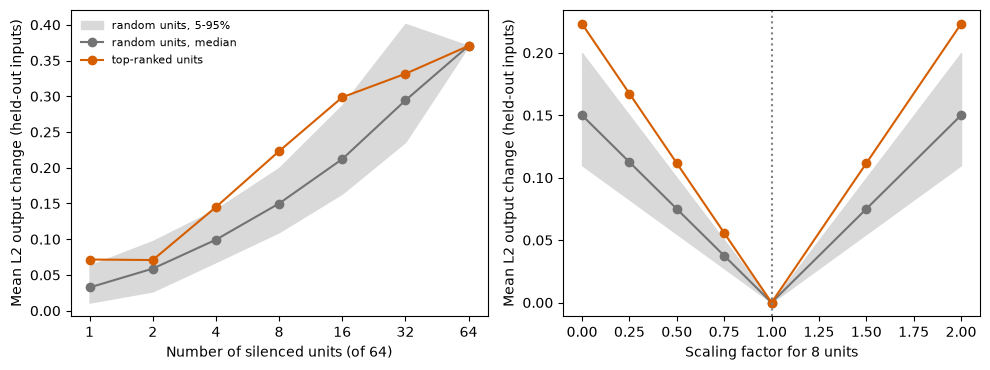

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, xs, ranked, rand, xlabel in [
    (axes[0], COUNTS, ranked_by_count, random_by_count, 'Number of silenced units (of 64)'),
    (axes[1], FACTORS, ranked_by_strength, random_by_strength, 'Scaling factor for 8 units'),
]:
    lo, med, hi = np.percentile(rand, [5, 50, 95], axis=1)
    ax.fill_between(xs, lo, hi, color='0.85', label='random units, 5-95%')
    ax.plot(xs, med, 'o-', color='0.45', label='random units, median')
    ax.plot(xs, ranked, 'o-', color='#D55E00', label='top-ranked units')
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Mean L2 output change (held-out inputs)')
axes[0].set_xscale('log', base=2)
axes[0].set_xticks(COUNTS, [str(k) for k in COUNTS])
axes[1].axvline(1.0, ls=':', c='0.5')
axes[0].legend(fontsize=8, frameon=False)
fig.tight_layout()
plt.show()

The same numbers as a table, with the fraction of random sets whose effect exceeded the ranked set.

In [8]:
count_table = pd.DataFrame({
    'units silenced': COUNTS,
    'top-ranked effect': np.round(ranked_by_count, 3),
    'random median': np.round(np.median(random_by_count, axis=1), 3),
    'random >= ranked (fraction)': [np.mean(r >= v) for r, v in zip(random_by_count, ranked_by_count)],
})
strength_table = pd.DataFrame({
    'scaling factor': FACTORS,
    'top-8 effect': np.round(ranked_by_strength, 3),
    'random-8 median': np.round(np.median(random_by_strength, axis=1), 3),
})
display(count_table)
display(strength_table)

,units silenced,top-ranked effect,random median,random >= ranked (fraction)
0,1,0.072,0.033,0.02
1,2,0.071,0.059,0.28
2,4,0.145,0.099,0.03
3,8,0.223,0.150,0.00
4,16,0.299,0.212,0.03
5,32,0.331,0.294,0.24
6,64,0.370,0.370,1.00


,scaling factor,top-8 effect,random-8 median
0,0.00,0.223,0.150
1,0.25,0.167,0.112
2,0.50,0.112,0.075
3,0.75,0.056,0.037
4,1.00,0.000,0.000
5,1.50,0.112,0.075
6,2.00,0.223,0.150


Silencing all 64 units changes the output by 0.370 for both selections. For 8 units, the top-ranked set changes the output by 0.223 and the median random set by 0.150; none of the 100 random sets of 8 reached the ranked effect. The ranked advantage is not uniform: at 2 and 32 units, 28% and 24% of random sets matched or exceeded the ranked set, and the ranked effect for 2 units (0.071) is no larger than for 1 unit (0.072).

The strength curve is symmetric around a factor of 1: scaling by 0.5 and by 1.5 both give 0.112 for the ranked set, and scaling by 0 and by 2 both give 0.223. This is expected here, because the change is applied before a ReLU and the rest of the network is linear in the size of the change for these inputs.

## Conclusion and limits

In this network the output change generally increases with the number of silenced units and with the distance of the scaling factor from 1. Ranking units by their individual effect on one set of inputs identifies units that usually have larger effects on new inputs than random units of the same number, but not at every selection size. The ranked and random selections converge as the selection approaches the whole layer, as they must.

The network is small and its weights are random, so the shape of these curves says nothing about trained networks or brains. In a trained network, effects can be redundant (several units carry the same information, so silencing a few does little) or can saturate early. The point of the experiment is the design: a dose axis, a held-out measurement set, and a size-matched random control. Lesson 8 shows how to build selections from localizer contrasts rather than from single-unit effects.

Back to the [notebook index](../README.md) and the [documentation](../../docs/README.md).